# Домашнее задание. Тема 10. Корреляция и корреляционный анализ

**Студент:** Кузнецов Данила, группа УЦП-25

**Датасет:** Mortality and Water Hardness — 61 большой город Англии и Уэльса: средняя годовая смертность на 100 000 населения (`mortality`) и жёсткость воды (`hardness`, мг/л CaCO3); города поделены на северные (`North`) и южные (`South`).

Данные загружаются из [raw.githubusercontent.com/vincentarelbun...]( https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/HSAUR/water.csv ) — зеркало классического датасета `water` (R-пакет HSAUR).

## Задание 1. Есть ли связь между жёсткостью воды и смертностью?

Шаги: точечный график → Пирсон и Спирмен → линейная регрессия → R² → график остатков.

### Шаг 0. Загрузка данных

In [1]:
import pandas as pd
import seaborn as sns
from scipy import stats


DATA_URL = ('https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/'
            'master/csv/HSAUR/water.csv')


def load_data(path):
    """Загружает данные о смертности и жёсткости воды."""
    df = pd.read_csv(path)
    return df[['location', 'town', 'mortality', 'hardness']]


def correlation_report(df):
    """Коэффициенты корреляции Пирсона и Спирмена с p-values."""
    pearson = stats.pearsonr(df['hardness'], df['mortality'])
    spearman = stats.spearmanr(df['hardness'], df['mortality'])
    return pearson, spearman


def fit_regression(df):
    """Линейная регрессия mortality ~ hardness (МНК)."""
    return stats.linregress(df['hardness'], df['mortality'])


df = load_data(DATA_URL)
print('строк:', len(df), '| пропусков:', int(df.isna().sum().sum()))
print(df.head(), end='\n\n')
print(df[['mortality', 'hardness']].describe().round(2))
print('\nГорода по регионам:')
print(df['location'].value_counts())

строк: 61 | пропусков: 0
             location           town  mortality  hardness
0     South            Bath       1247       105
1     North      Birkenhead     1668        17
2     South     Birmingham    1466         5
3     North      Blackburn     1800        14
4     North  Blackpool        1600        18

      mortality  hardness
count      61.00     61.00
mean     1524.15     47.18
std       187.67     38.09
min      1096.00      5.00
25%      1379.00     14.00
50%      1555.00     39.00
75%      1668.00     75.00
max      1987.00    138.00

Города по регионам:
location
North    35
South    26
Name: count, dtype: int64


### Шаг 1. Точечный график

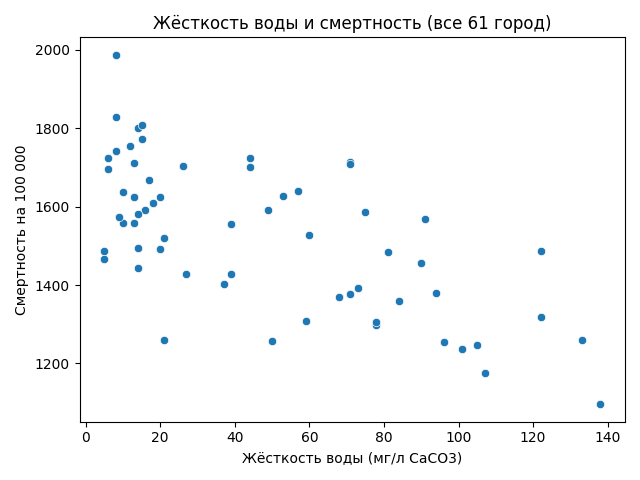

In [2]:
axes = sns.scatterplot(data=df, x='hardness', y='mortality')
axes.set_title('Жёсткость воды и смертность (все 61 город)')
axes.set_xlabel('Жёсткость воды (мг/л CaCO3)')
axes.set_ylabel('Смертность на 100 000');

### Шаг 2. Коэффициенты корреляции Пирсона и Спирмена

In [3]:
pearson, spearman = correlation_report(df)
print(f'Коэффициент корреляции Пирсона: {pearson.statistic:.4f} (p-value = {pearson.pvalue:.2e})')
print(f'Коэффициент корреляции Спирмена: {spearman.statistic:.4f} (p-value = {spearman.pvalue:.2e})')

Коэффициент корреляции Пирсона: -0.6548 (p-value = 1.03e-08)
Коэффициент корреляции Спирмена: -0.6317 (p-value = 4.80e-08)


### Шаг 3. Модель линейной регрессии и шаг 4. Коэффициент детерминации

In [4]:
reg = fit_regression(df)
print(f'Уравнение регрессии: mortality = {reg.intercept:.2f} + ({reg.slope:.4f}) * hardness')
print(f'Коэффициент детерминации R^2 = {reg.rvalue ** 2:.4f}')

Уравнение регрессии: mortality = 1676.36 + (-3.2261) * hardness
Коэффициент детерминации R^2 = 0.4288


### Шаг 5. График остатков

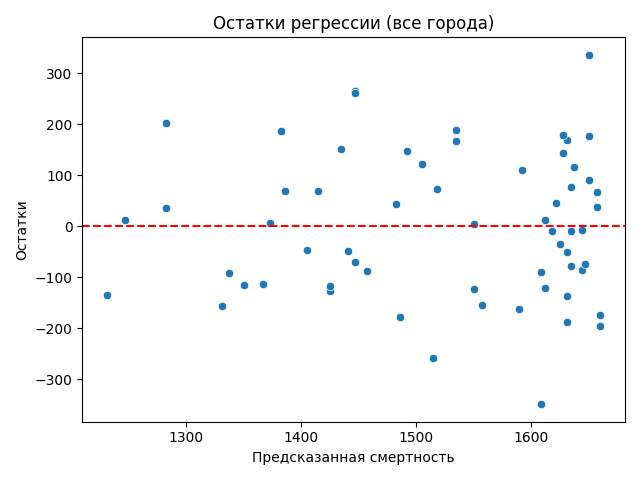

In [5]:
import matplotlib.pyplot as plt

fitted = reg.intercept + reg.slope * df['hardness']
residuals = df['mortality'] - fitted
axes = sns.scatterplot(x=fitted, y=residuals)
axes.axhline(0, color='red', linestyle='--')
axes.set_title('График остатков (все города)')
axes.set_xlabel('Предсказанная смертность')
axes.set_ylabel('Остатки');
plt.show();

**Вывод по заданию 1:** связь есть и она **отрицательная**. Пирсон −0.6548 и Спирмен −0.6317 (оба p-value << 0.001) — заметная монотонная связь: чем жёстче питьевая вода, тем **ниже** средняя годовая смертность. Регрессия `mortality = 1676.36 − 3.23 × hardness` объясняет ~42.9% дисперсии (R² = 0.4288), то есть каждый +10 мг/л жёсткости соответствует −32 смерти на 100 000 в год. Остатки разбросаны вокруг нуля без явной структуры — линейная модель адекватна. Корреляция ≠ причинность: жёсткость воды — маркер региона (Север/Юг), а не лекарство.

## Задание 2. Северные и южные города по отдельности

### Северные города

Северные города (n=35)
Пирсон: -0.3686 | Спирмен: -0.4042
Уравнение: mortality = 1692.31 + (-1.9313) * hardness
R^2 = 0.1359


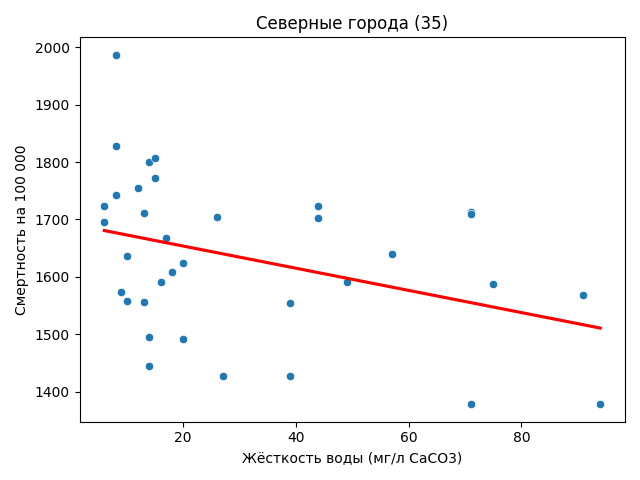

In [6]:
north = df[df['location'] == 'North']
pearson_n, spearman_n = correlation_report(north)
reg_n = fit_regression(north)
print(f'Северные города (n={len(north)})')
print(f'Пирсон: {pearson_n.statistic:.4f} | Спирмен: {spearman_n.statistic:.4f}')
print(f'Уравнение: mortality = {reg_n.intercept:.2f} + ({reg_n.slope:.4f}) * hardness')
print(f'R^2 = {reg_n.rvalue ** 2:.4f}')

### Южные города

Южные города (n=26)
Пирсон: -0.6022 | Спирмен: -0.5957
Уравнение: mortality = 1522.82 + (-2.0927) * hardness
R^2 = 0.3626


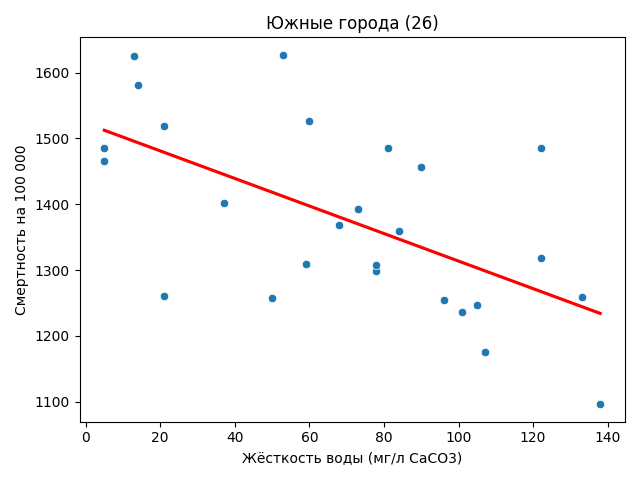

In [7]:
south = df[df['location'] == 'South']
pearson_s, spearman_s = correlation_report(south)
reg_s = fit_regression(south)
print(f'Южные города (n={len(south)})')
print(f'Пирсон: {pearson_s.statistic:.4f} | Спирмен: {spearman_s.statistic:.4f}')
print(f'Уравнение: mortality = {reg_s.intercept:.2f} + ({reg_s.slope:.4f}) * hardness')
print(f'R^2 = {reg_s.rvalue ** 2:.4f}')

axes = sns.regplot(data=south, x='hardness', y='mortality', ci=None,
                   line_kws={'color': 'red'})
axes.set_title('Южные города: scatter с линией регрессии')
axes.set_xlabel('Жёсткость воды (мг/л CaCO3)')
axes.set_ylabel('Смертность на 100 000');
plt.show();

**Вывод по заданию 2:** отрицательная зависимость **сохраняется в обеих группах**, но выражена по-разному:

- **Юг**: Пирсон −0.6022, R² = 0.3626 — сильная связь, близкая к общей.
- **Север**: Пирсон −0.3686 (Спирмен −0.4042), R² = 0.1359 — связь заметно слабее и объясняет лишь ~14% дисперсии.

Итог: общая корреляция по всей выборке усиливается за счёт южных городов; на севере разброс выше и связь слабее — вероятно, на смертность там сильнее влияют другие факторы (промышленность, климат, состав воды помимо кальция). Парадокс Симпсона не наблюдается: направление связи везде одинаково (отрицательное).